# Building Defect AI — Notebook workflow

Run from the repository root. Expected data layout: `dataset/BD3_split/{train,val,test}/<class_name>/...`.

**Task:** classify images into the seven BD3 labels. This notebook records the method, why it is used, the result and its interpretation. Do not treat model predictions as professional inspection findings.

In [1]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader

from PIL import Image

# Automatically detect project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    ROOT = CURRENT_DIR.parent
else:
    ROOT = CURRENT_DIR

# Project paths
DATA = ROOT / "dataset" / "BD3_split"
MODEL_PATH = ROOT / "models" / "building_defect_resnet18_experiment3.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", ROOT)
print("Dataset:", DATA)
print("Device:", DEVICE)

assert DATA.exists(), f"Dataset not found: {DATA}"

print("Project paths verified successfully.")

Project root: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI
Dataset: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI\dataset\BD3_split
Device: cuda
Project paths verified successfully.


## 1. Load dataset metadata

`ImageFolder` infers labels from subfolder names. This keeps labels consistent with the directory structure. We inspect counts before training because class imbalance can affect metrics.

In [2]:
from collections import Counter
from torchvision.datasets import ImageFolder
splits = {}
for split in ["train", "val", "test"]:
    ds = ImageFolder(DATA / split)
    splits[split] = ds
    print(f"\\n{split}: {len(ds)} images")
    print(dict(Counter(ds.targets)))
print("Class order:", splits["train"].classes)
for split, ds in splits.items():
    assert ds.classes == splits["train"].classes, f"Class order mismatch in {split}"


\ntrain: 2378 images
{0: 372, 1: 348, 2: 374, 3: 312, 4: 360, 5: 300, 6: 312}
\nval: 792 images
{0: 124, 1: 116, 2: 124, 3: 104, 4: 120, 5: 100, 6: 104}
\ntest: 795 images
{0: 124, 1: 116, 2: 126, 3: 104, 4: 120, 5: 100, 6: 105}
Class order: ['algae', 'major_crack', 'minor_crack', 'peeling', 'plain', 'spalling', 'stain']


## 2. Visualise class distribution

A bar chart reveals whether some classes are represented much more often than others. It does not by itself prove the model will be biased, but it helps interpret per-class recall.

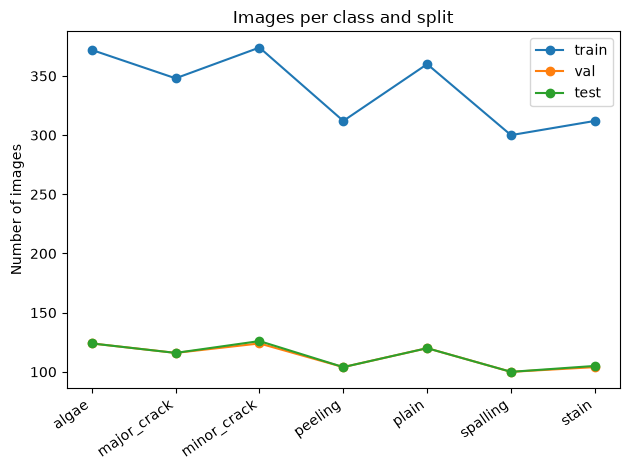

In [3]:
import matplotlib.pyplot as plt
counts = {s: [splits[s].targets.count(i) for i in range(len(splits[s].classes))] for s in splits}
x = range(len(splits["train"].classes))
for s, vals in counts.items():
    plt.plot(list(x), vals, marker="o", label=s)
plt.xticks(list(x), splits["train"].classes, rotation=35, ha="right")
plt.ylabel("Number of images"); plt.title("Images per class and split"); plt.legend(); plt.tight_layout(); plt.show()


## 3. Interpretation of Dataset Distribution

The BD3 dataset contains 3,965 images distributed across seven building-surface categories:

- algae
- major_crack
- minor_crack
- peeling
- plain
- spalling
- stain

The dataset was divided into three subsets:

| Subset | Images | Percentage |
|---|---:|---:|
| Training | 2,378 | 60% |
| Validation | 792 | 20% |
| Testing | 795 | 20% |
| **Total** | **3,965** | **100%** |

### Class distribution observations

The class-distribution visualisation shows broadly similar representation across the seven categories. No class is completely absent or overwhelmingly dominant.

However, equal or similar image counts do not guarantee equal classification difficulty.

For example:
- Major and minor cracks may have visually similar textures.
- Algae and stain may have overlapping colour and surface characteristics.
- Peeling and spalling may exhibit similar surface deterioration patterns.
- Plain surfaces provide a useful non-defect comparison category.

### Why this matters for model training

A reasonably balanced dataset reduces the likelihood that the model will achieve high overall accuracy simply by predicting the most frequent category.

However, the model must still learn meaningful visual differences between similar classes.

### Conclusion

The dataset provides a suitable starting point for a seven-class image-classification experiment.

The next challenge is not simply learning the appearance of each category, but distinguishing visually similar surface conditions.

A further investigation of duplicate and near-duplicate images across the three subsets is necessary before claiming that the test results represent fully independent generalisation.